In [ ]:
import os
from pathlib import Path
import json
from truckscenes.truckscenes import TruckScenes
DATA_ROOT = Path("../data/raw/man-truckscenes")
VERSION = "v1.0-mini"

if not DATA_ROOT.exists():
    print(f"Lỗi: Không tìm thấy dataset tại đường dẫn: {DATA_ROOT.resolve()}")
    print("Hãy đảm bảo bạn đã giải nén dataset vào đúng thư mục data/raw/")
else:
    print(f"Đã tìm thấy dataset tại: {DATA_ROOT.resolve()}")

Đã tìm thấy dataset tại: D:\app\SafeTruckVision\data\raw\man-truckscenes


In [ ]:
print("Đang tải metadata của dataset... (có thể mất vài giây)")
ts = TruckScenes(dataroot=DATA_ROOT, version=VERSION)
print("Tải thành công!")

Đang tải metadata của dataset... (có thể mất vài giây)
Loading truckscenes tables for version v1.0-mini...
11 attribute,
18 calibrated_sensor,
27 category,
20090 ego_motion_cabin,
20089 ego_motion_chassis,
20116 ego_pose,
1094 instance,
400 sample,
25750 sample_annotation,
43556 sample_data,
10 scene,
18 sensor,
4 visibility,
Done loading in 1.218 seconds.
Reverse indexing ...
Done reverse indexing in 0.3 seconds.
Tải thành công!


d:\Anaconda_envs\safetruck_env\lib\site-packages\truckscenes\truckscenes.py:93: UserWarning: The visualization dependencies are not installed on your system! Run 'pip install "truckscenes-devkit[all]"'.
  warnings.warn('''The visualization dependencies are not installed on your system! '''


In [ ]:
print(f"Tổng số scenes trong bộ '{VERSION}': {len(ts.scene)}")
print("-------------------------------------------------")

first_scene = ts.scene[0]

print("--- DỮ LIỆU CỦA SCENE ĐẦU TIÊN ---")
print(json.dumps(first_scene, indent=2))
print("-------------------------------------------------")

first_sample_token = first_scene["first_sample_token"]
first_sample = ts.get("sample", first_sample_token)

print("--- DỮ LIỆU CỦA SAMPLE ĐẦU TIÊN (trong scene 0) ---")
print(json.dumps(first_sample, indent=2))

Tổng số scenes trong bộ 'v1.0-mini': 10
-------------------------------------------------
--- DỮ LIỆU CỦA SCENE ĐẦU TIÊN ---
{
  "name": "scene-0044384af3d8494e913fb8b14915239e-3",
  "description": "weather.clear;area.terminal;daytime.noon;season.autumn;lighting.illuminated;structure.regular;construction.unchanged",
  "token": "044c648ac12345f1aedf33c9f91cdc5a",
  "log_token": "",
  "nbr_samples": 40,
  "first_sample_token": "32d2bcf46e734dffb14fe2e0a823d059",
  "last_sample_token": "94640f753b284a1c9c0e8694243f60cd"
}
-------------------------------------------------
--- DỮ LIỆU CỦA SAMPLE ĐẦU TIÊN (trong scene 0) ---
{
  "token": "32d2bcf46e734dffb14fe2e0a823d059",
  "scene_token": "044c648ac12345f1aedf33c9f91cdc5a",
  "timestamp": 1695473372698161,
  "prev": "",
  "next": "deb7b3f332f042d49e7636d6e4959354",
  "data": {
    "RADAR_RIGHT_BACK": "c790efd2151d491aae635234a5df26d8",
    "RADAR_RIGHT_SIDE": "7f3083ba7f2e49678b4ccbc2fd14f590",
    "RADAR_RIGHT_FRONT": "36c9a2c6b3ee4d9f9d01

In [ ]:
available_cameras = set()

for s in ts.sample:
    for sensor_name in s['data'].keys():
        if sensor_name.startswith("CAMERA_"):
            available_cameras.add(sensor_name)

if not available_cameras:
    print("LỖI: Không tìm thấy BẤT KỲ camera nào trong bộ v1.0-mini này.")
else:
    print("Đã tìm thấy các camera sau đây trong bộ mini:")
    print(available_cameras)

✅ Tuyệt vời! Đã tìm thấy các camera sau đây trong bộ mini:
{'CAMERA_RIGHT_BACK', 'CAMERA_LEFT_BACK', 'CAMERA_LEFT_FRONT', 'CAMERA_RIGHT_FRONT'}


In [ ]:
TARGET_CAM = 'CAMERA_RIGHT_FRONT'

good_sample = None
for s in ts.sample:
    if TARGET_CAM in s['data']:
        good_sample = s
        break

if good_sample:
    print(f"✅ Đã tìm thấy 1 sample tốt dùng camera '{TARGET_CAM}'. Bắt đầu phân tích:")
    
    if not good_sample["anns"]:
        print(f"LỖI: Sample này có camera nhưng không có nhãn (annotation) nào.")
    else:
        first_ann_token = good_sample["anns"][0] 
        first_ann = ts.get("sample_annotation", first_ann_token)
        print("--- DỮ LIỆU CỦA NHÃN ĐẦU TIÊN (trong sample tốt) ---")
        print(json.dumps(first_ann, indent=2))
        print("-------------------------------------------------")

        cam_data_token = good_sample["data"][TARGET_CAM]
        cam_data = ts.get("sample_data", cam_data_token)
        calib_sensor_token = cam_data["calibrated_sensor_token"]
        calib_data = ts.get("calibrated_sensor", calib_sensor_token)
        print(f"--- DỮ LIỆU HIỆU CHỈNH (CALIBRATION) CỦA {TARGET_CAM} ---")
        print(json.dumps(calib_data, indent=2))
    
else:
    print(f"LỖI: Không tìm thấy sample nào dùng camera '{TARGET_CAM}'.")

✅ Đã tìm thấy 1 sample tốt dùng camera 'CAMERA_RIGHT_FRONT'. Bắt đầu phân tích:
--- DỮ LIỆU CỦA NHÃN ĐẦU TIÊN (trong sample tốt) ---
{
  "token": "50873dd5195b47bc9544ac2821e054e0",
  "sample_token": "32d2bcf46e734dffb14fe2e0a823d059",
  "instance_token": "163b7c695f7243779ef5e5f0fd844063",
  "visibility_token": "6adc1826065b452195ae6a76317b8ab5",
  "attribute_tokens": [
    "eefd82c9b2f144e2b1c61a432254cff2"
  ],
  "translation": [
    571701.2157594472,
    5367870.003885938,
    594.4508582291495
  ],
  "size": [
    1.66326,
    3.745129,
    1.473757
  ],
  "rotation": [
    0.9844024900258261,
    -4.336808689942018e-19,
    4.336808689942018e-19,
    0.17593105931288455
  ],
  "prev": "",
  "next": "9f0e8f997dc647bf9a0a20c679b1804d",
  "num_lidar_pts": 430,
  "num_radar_pts": 2,
  "category_name": "vehicle.car"
}
-------------------------------------------------
--- DỮ LIỆU HIỆU CHỈNH (CALIBRATION) CỦA CAMERA_RIGHT_FRONT ---
{
  "token": "ef56b5089358479d8e007355933f40dc",
  "se

In [13]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from pyquaternion import Quaternion
from truckscenes.utils.data_classes import Box

print("Tải xong các thư viện CV và Toán học.")

Tải xong các thư viện CV và Toán học.


In [ ]:
if 'good_sample' in locals():
    target_cam = 'CAMERA_RIGHT_FRONT'
    cam_data_token = good_sample['data'][target_cam]

    cam_data = ts.get('sample_data', cam_data_token)
    image_path = DATA_ROOT / VERSION / cam_data['filename']
    ann_box_3d = Box(
        center=first_ann['translation'],
        size=first_ann['size'],
        orientation=Quaternion(first_ann['rotation'])
    )

    corners_3d_world = ann_box_3d.corners()
    
    print(f"Đã lấy được đường dẫn ảnh (ĐÃ SỬA): {image_path}")
    print(f"Kiểm tra file tồn tại: {image_path.exists()}") # Sẽ in ra True
    print(f"Đã lấy 8 điểm góc 3D (shape {corners_3d_world.shape})")
else:
    print("Lỗi: Không tìm thấy 'good_sample'. Vui lòng chạy lại Cell 4.")

Đã lấy được đường dẫn ảnh (ĐÃ SỬA): ..\data\raw\man-truckscenes\v1.0-mini\samples\CAMERA_RIGHT_FRONT\CAMERA_RIGHT_FRONT_1695473372700156.jpg
Kiểm tra file tồn tại: True
Đã lấy 8 điểm góc 3D (shape (3, 8))


In [ ]:

if 'corners_3d_world' in locals():
    cam_data = ts.get('sample_data', cam_data_token)
    calib_data = ts.get('calibrated_sensor', cam_data['calibrated_sensor_token'])
    cam_intrinsic = np.array(calib_data['camera_intrinsic'])
    cam_translation = np.array(calib_data['translation'])
    cam_rotation = Quaternion(calib_data['rotation'])

    ego_pose_token = cam_data['ego_pose_token']
    ego_pose = ts.get('ego_pose', ego_pose_token)
    ego_translation = np.array(ego_pose['translation'])
    ego_rotation = Quaternion(ego_pose['rotation'])

    corners_in_ego_frame = corners_3d_world - ego_translation.reshape(3, 1)

    ego_rotation_matrix = ego_rotation.inverse.rotation_matrix
    corners_in_ego_frame = ego_rotation_matrix @ corners_in_ego_frame

    corners_in_cam_frame = corners_in_ego_frame - cam_translation.reshape(3, 1)

    cam_rotation_matrix = cam_rotation.inverse.rotation_matrix
    corners_in_cam_frame = cam_rotation_matrix @ corners_in_cam_frame

    points_3d = corners_in_cam_frame
    depths = points_3d[2, :]

    projected_points = cam_intrinsic @ points_3d
    points_2d = projected_points[:2, :] / projected_points[2, :]
    
    valid_mask = depths > 0
    valid_points_2d = points_2d[:, valid_mask]

    if valid_points_2d.shape[1] < 2:
        print("Lỗi: Hộp 3D nằm hoàn toàn sau camera, không thể vẽ.")
    else:
        x_min = int(np.min(valid_points_2d[0, :]))
        y_min = int(np.min(valid_points_2d[1, :]))
        x_max = int(np.max(valid_points_2d[0, :]))
        y_max = int(np.max(valid_points_2d[1, :]))
        
        box_2d = (x_min, y_min, x_max, y_max)
        print(f"✅ Chiếu thành công! Tọa độ Hộp 2D là: {box_2d}")
else:
    print("Lỗi: Không tìm thấy 'corners_3d_world'. Vui lòng chạy lại Cell 6.")

✅ Chiếu thành công! Tọa độ Hộp 2D là: (1002, 542, 1147, 605)


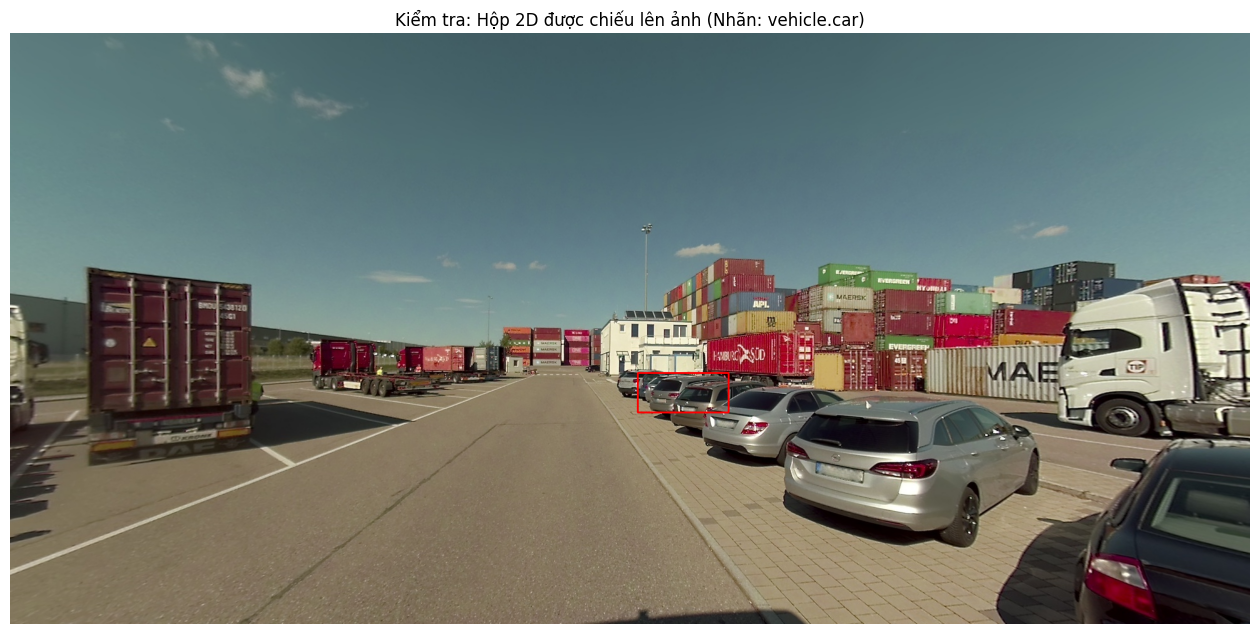

In [ ]:
if 'box_2d' in locals():
    image = cv2.imread(str(image_path))
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    cv2.rectangle(
        image, 
        (x_min, y_min), 
        (x_max, y_max), 
        (255, 0, 0),
        2
    )

    plt.figure(figsize=(16, 9))
    plt.imshow(image)
    plt.title(f"Kiểm tra: Hộp 2D được chiếu lên ảnh (Nhãn: {first_ann['category_name']})")
    plt.axis('off')
    plt.show()

else:
    print("Lỗi: Không tìm thấy 'box_2d'. Vui lòng chạy lại Cell 7.")